# Module 7 — Apollo Root Cause Analysis & Cause Mapping

Part of the Root-Cause Analysis Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- The 5 Whys draws one chain. A fishbone draws a list. Neither shows how causes **combine**.
- Apollo root cause analysis draws a map: every effect has at least two causes acting together, an **action** (something that happened) and a **condition** (something that was true), and every cause carries its evidence.
- In DMAIC (Define, Measure, Analyze, Improve, Control), it is an **Analyze** tool. It also prepares Improve: a fix can go at any cause on the map.

**What this module produces:**
1. Three alarming headlines from a real public-data report, each traced to its pair of causes with evidence.
2. A cause map that links them to one goal, with the one cause the data cannot support marked as missing evidence.
3. A table of where a fix could go, cause by cause.

## From the curriculum

> ## <u>Module 7 — Apollo Root Cause Analysis & Cause Mapping</u>
>
> **DMAIC phase:** Analyze (causes as a graph, each backed by evidence).
>
> **Concepts**
> - Apollo RCA (Dean Gano's method, described in his book *Apollo Root Cause
>   Analysis*): every effect has at least two causes acting together, an
>   action (something that happened) and a condition (something that was
>   true)
> - Cause-and-effect charts that branch and join, rather than one line of
>   "whys"
> - Evidence attached to every cause, and causes with no evidence marked as
>   such
> - Solutions placed at any cause in the chart, not only at the "root": often
>   the cheapest fix is at the condition
> - Cause mapping (ThinkReliability's variant): starting from the impact on a
>   goal
>
> **Why it matters**
> Real incidents usually need several causes at once. A map shows which
> combination was needed, so a fix can target the cause in the combination that
> is easiest to change.
>
> **Worked example**
> The E09 / E12 NYC 311 investigation (reuse), on public data re-fetched from
> NYC Open Data and frozen. An August 2026 report on 311 service requests had
> three alarming headlines, and each turns out to need its own pair of causes:
> - **A water-and-sewer "surge":** a July label change at the
>   Department of Environmental Protection (DEP), combined with a report that
>   counts labels separately.
> - **A closure-rate "collapse":** a young month compared with an old one,
>   combined with requests that keep closing for weeks.
> - **A rise in housing requests:** more were filed, but the condition behind
>   it is unknown, and the map marks it as missing evidence.
>
> **Resources**
> - [Apollo Root Cause Analysis](https://realitycharting.com/apollo-root-cause-analysis-problem-solving-methodology)
>   (Reality Charting, ~5 min, verified): the method's four steps, from the
>   company Dean Gano founded. The actions-and-conditions principle is in his
>   book, not on this page.
> - [Cause Mapping](https://www.thinkreliability.com/cause-mapping/)
>   (ThinkReliability, ~5 min, verified): the cause-mapping variant, which
>   starts from the goal that was hurt and looks for several causes working
>   together.
>
> **Exercise type:** place a manager's claim on the cause map and check it
> against the evidence. Fully worked.
>
> **Interview angle:** "What if there's more than one root cause?"

## Lesson

### Actions and conditions

Apollo's central rule (from Dean Gano's book): an effect never has just one cause. It needs at least:
- an **action**: something that happened (*"the label was changed"*)
- a **condition**: something that was already true and let the action have its effect (*"the report counts each label separately"*)

Remove either one and the effect does not happen. That is why "the root cause" is usually the wrong question: there are at least two, and either can be the place to fix.

### The cause map

- Start from the effect, on the left, and work right: each effect points to the causes that produced it.
- Each cause can itself be an effect with its own causes, so the map branches.
- **Every cause carries evidence:** the data that shows it is true. A cause with no evidence stays on the map, marked as missing evidence (a Hypothesis).

### Solutions at any cause

Because each effect needs both its action and its condition, removing **either** prevents it. Often the action cannot be undone (a past event, a deliberate business decision) but the condition can be changed cheaply. Cause mapping (ThinkReliability's variant) adds one more habit: start from the **goal that was hurt**, so the map stays tied to what actually matters.

### How it differs from the earlier techniques

- **5 Whys (Module 5):** one chain. It missed a second cause.
- **Fishbone (Module 6):** a list of candidates, with no links between them.
- **Cause map:** links causes to effects, in pairs, with evidence on each.

## Worked example: an alarming August 2026 report on NYC 311

**Data choice: reuse, re-fetched.** The user's E09 and E12 exercises investigated why an August 2026 report on NYC 311 service requests (311 is New York City's non-emergency service line) showed three alarming changes. Each change turned out to have its own causes, and a cause map shows several causes best. The data is public, so this module re-fetches it from NYC Open Data instead of using a local copy.

**Where this was already done, unnamed:** the user's E09 and E12 exercises (`AI Analyst Workspace/Reports/E09_Summary.md` and `E12_Summary.md`, local files).

**The data:** only aggregates (counts), fetched once by `data/fetch_nyc311.py` and frozen in `data/raw/nyc311/` with a checksum per file, so the notebook always runs on the same numbers.

**The goal that was hurt:** a monthly report that leaders use to decide where 311 service needs help. The report itself is not public. It is rebuilt here from the frozen data: its three headlines are the comparisons that E09 and E12 examined. For August 2026 it showed three alarming headlines:
1. the Department of Environmental Protection's (DEP's) water and sewer requests "surged"
2. the share of requests closed "collapsed"
3. requests to the Department of Housing Preservation and Development (HPD, the city's housing agency) rose sharply

Each headline is an effect. The question for each: which action and which condition produced it?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import common
from common import show, BLUE, ORANGE, AQUA, GREY

d = common.load_nyc311()
cl = d["august_closure"].drop_duplicates()
get = lambda month, measure: int(cl.query("month == @month and measure == @measure")["n"].iloc[0])
print(f"Snapshot fetched = {d['manifest']['fetched_at']}")
print()
print("Does the snapshot match the original E09 / E12 analyses? (E09 and E12 pulled the data on 15.09.2026)")
print(f"  August 2026 requests: now = {get('2026-08', 'requests'):,}, E09 = 328,701, difference = {get('2026-08', 'requests') - 328701:+,} = {(get('2026-08', 'requests') - 328701) / 328701:+.2%}")
print(f"  August 2025 requests: now = {get('2025-08', 'requests'):,}, E09 = 304,039, difference = {get('2025-08', 'requests') - 304039:+,}")

Snapshot fetched = 2026-10-14 12:30 UTC

Does the snapshot match the original E09 / E12 analyses? (E09 and E12 pulled the data on 15.09.2026)
  August 2026 requests: now = 328,914, E09 = 328,701, difference = +213 = +0.06%
  August 2025 requests: now = 304,039, E09 = 304,039, difference = +0


**Observation:** August 2025 matches E09 exactly. August 2026 has 213 more requests now than when E09 pulled it. The difference is 0.06%, too small to change any finding below.

**Hypothesis:** the city adds late records to recent months. That is a reminder that public data is revised over time, which is why this snapshot is frozen.

### Effect 1 — the water-and-sewer "surge"

Each request carries a label (the complaint-type field, e.g. "Sewer"). What did the report show? DEP's requests with the labels "Water Maintenance" and "Sewer Maintenance", month by month:

In [2]:
m = d["dep_labels_monthly"].copy()
m["month"] = pd.to_datetime(m["month"]).dt.strftime("%Y-%m")
p = m.pivot_table(index="month", columns="complaint_type", values="n", aggfunc="sum").fillna(0).astype(int)
p["new labels"] = p["Water Maintenance"] + p["Sewer Maintenance"]
p["old labels"] = p["Water System"] + p["Sewer"]
p["all four labels"] = p["new labels"] + p["old labels"]
print("DEP water and sewer requests by month (old labels = Water System + Sewer, new labels = Water Maintenance + Sewer Maintenance):\n")
show(p[["Water System", "Sewer", "Water Maintenance", "Sewer Maintenance", "old labels", "new labels", "all four labels"]], index=True)
nl = p["new labels"]
print(f"\nWhat the report showed: new labels, July 2026 = {nl['2026-07']:,}, August 2026 = {nl['2026-08']:,}, change = {nl['2026-08'] / nl['2026-07'] - 1:+.0%}")
al = p["all four labels"]
print("All four labels together, August 2026 against:")
print(f"  July 2026 = {al['2026-07']:,}, change = {al['2026-08'] / al['2026-07'] - 1:+.1%}")
print(f"  August 2025 = {al['2025-08']:,}, change = {al['2026-08'] / al['2025-08'] - 1:+.1%}")

DEP water and sewer requests by month (old labels = Water System + Sewer, new labels = Water Maintenance + Sewer Maintenance):

month    Water System  Sewer  Water Maintenance  Sewer Maintenance  old labels  new labels  all four labels
2025-08          7118   2475                 11                  4        9593          15             9608
2025-09          4194   1850                  8                 11        6044          19             6063
2025-10          5036   3550                  8                 18        8586          26             8612
2025-11          3646   2161                 15                  6        5807          21             5828
2025-12          4189   1998                 14                 10        6187          24             6211
2026-01          6292   1550                 25                 11        7842          36             7878
2026-02          7988   1769                 28                 24        9757          52             9809
2026-03 

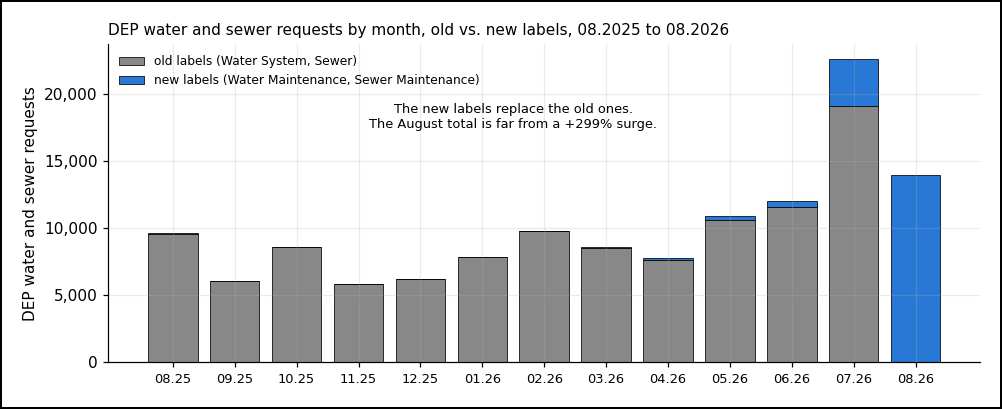

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
x = np.arange(len(p))
ax.bar(x, p["old labels"], color=GREY, edgecolor="black", linewidth=0.5, label="old labels (Water System, Sewer)")
ax.bar(x, p["new labels"], bottom=p["old labels"], color=BLUE, edgecolor="black", linewidth=0.5, label="new labels (Water Maintenance, Sewer Maintenance)")
ax.set_xticks(x, [pd.Timestamp(i).strftime("%m.%y") for i in p.index], fontsize=8.5)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylabel("DEP water and sewer requests")
ax.set_title("DEP water and sewer requests by month, old vs. new labels, 08.2025 to 08.2026", fontsize=10, loc="left")
ax.text(5.5, 17500, "The new labels replace the old ones.\nThe August total is far from a +299% surge.", ha="center", fontsize=8.5)
ax.legend(fontsize=8, frameon=False, loc="upper left")
plt.tight_layout(); plt.show()

In [4]:
dd = d["dep_labels_daily"].copy()
dd["day"] = pd.to_datetime(dd["day"])
old_days = dd[dd["complaint_type"].isin(["Water System", "Sewer"])]
dd["week"] = dd["day"].dt.to_period("W-SUN").dt.start_time
wk = dd.assign(new=dd["complaint_type"].isin(["Water Maintenance", "Sewer Maintenance"])).groupby(["week", "new"])["n"].sum().unstack(fill_value=0)
wk = wk[(wk.index >= "2026-05-04") & (wk.index <= "2026-08-24")]  # whole weeks only (Monday to Sunday)
print("When did the switch happen? Every week from May to August 2026:")
print("(share of new labels = new labels ÷ all four labels)\n")
show(pd.DataFrame({"week": [f"{w:%d.%m} to {w + pd.Timedelta(days=6):%d.%m}" for w in wk.index], "new labels": [f"{v:,}" for v in wk[True]],
                   "all four labels": [f"{v:,}" for v in wk.sum(axis=1)], "share of new labels": [f"{v:.1%}" for v in wk[True] / wk.sum(axis=1)]}))
print(f"\nLast day with an old-label request = {old_days['day'].max():%d.%m.%Y}")

When did the switch happen? Every week from May to August 2026:
(share of new labels = new labels ÷ all four labels)

week            new labels  all four labels  share of new labels
04.05 to 10.05          75            1,677                 4.5%
11.05 to 17.05          54            1,759                 3.1%
18.05 to 24.05          94            4,859                 1.9%
25.05 to 31.05          64            2,131                 3.0%
01.06 to 07.06          45            2,641                 1.7%
08.06 to 14.06         116            3,703                 3.1%
15.06 to 21.06         105            2,424                 4.3%
22.06 to 28.06         129            2,251                 5.7%
29.06 to 05.07         219           10,554                 2.1%
06.07 to 12.07         452            3,946                11.5%
13.07 to 19.07         546            4,407                12.4%
20.07 to 26.07         884            2,802                31.5%
27.07 to 02.08       2,011           

**Observation:** the new labels stayed a small share in May and June (1.7% to 5.7% a week). They rose to 11.5% and 12.4% in the first two weeks of July, then took over: 31.5% in the week of 20.07 to 26.07, 82.1% the week after, 100% from 03.08. The last old-label request was on 29.07.2026, so the switch was complete from 30.07. (The week starting 31.08 has only one day in August, so it is left out.)

**Observation:** counted together, the four labels show no +299% surge. They went from 22,591 in July to 13,985 in August, −38.1%. Against August 2025 (9,608) they are up 45.6%.

**Hypothesis (out of scope for this map):** July 2026 is the highest month in the table, so the −38.1% partly reflects an unusual July. The +45.6% against August 2025 may be a real rise in water and sewer problems. Both are worth their own look. Neither is the report's +299%.

**The cause pair:**
- **Action:** DEP replaced the old labels with new ones, starting in early July and complete from 30.07 (evidence: the weekly label shares above).
- **Condition:** the report counts each label separately, with no table mapping old labels to new ones (evidence: the +299% only appears when the new labels are counted alone. All four together fall 38.1% from July).

Remove either one and the "surge" disappears: no relabel, or a report that adds old and new labels together.

### Effect 2 — the closure-rate "collapse"

The report compared the share of August requests that were closed, this year against last year:

In [5]:
r25, r26 = get("2025-08", "requests"), get("2026-08", "requests")
rows = [("August 2025, measured 13 months later (15.09.2026)", get("2025-08", "closed by 2026-09-15"), r25),
        ("August 2026, measured 6 weeks later (15.09.2026)", get("2026-08", "closed by 2026-09-15"), r26),
        ("August 2025, measured 6 weeks later (15.09.2025)", get("2025-08", "closed by 2025-09-15"), r25),
        ("August 2026, measured 10 weeks later (14.10.2026)", get("2026-08", f"closed by {d['manifest']['fetched_at'][:10]}"), r26)]
s = [r[1] / r[2] for r in rows]
print("Share of August requests closed (closed = has a closed date on or before the measuring date):")
print("(age = time from 1 August to the measuring date)\n")
show(pd.DataFrame({"what is compared": [r[0] for r in rows], "closed": [f"{r[1]:,}" for r in rows], "requests": [f"{r[2]:,}" for r in rows],
                   "share closed": [f"{v:.2%}" for v in s]}))
print()
print("The report's comparison, August 2026 at 6 weeks against August 2025 at 13 months:")
print(f"  gap = {s[1]:.2%} − {s[0]:.2%} = {(s[1] - s[0]) * 100:+.2f} points")
print(f"  change = {s[1]:.2%} ÷ {s[0]:.2%} − 1 = {s[1] / s[0] - 1:+.1%}")
print("The same comparison at equal age, 6 weeks each:")
print(f"  gap = {s[1]:.2%} − {s[2]:.2%} = {(s[1] - s[2]) * 100:+.2f} points")
print("The part of the gap that comes only from the unequal ages (August 2025 at 13 months against at 6 weeks):")
print(f"  {s[0]:.2%} − {s[2]:.2%} = {(s[0] - s[2]) * 100:.2f} points")

Share of August requests closed (closed = has a closed date on or before the measuring date):
(age = time from 1 August to the measuring date)

what is compared                                     closed  requests  share closed
August 2025, measured 13 months later (15.09.2026)  298,538   304,039        98.19%
August 2026, measured 6 weeks later (15.09.2026)    294,883   328,914        89.65%
August 2025, measured 6 weeks later (15.09.2025)    279,746   304,039        92.01%
August 2026, measured 10 weeks later (14.10.2026)   310,444   328,914        94.38%

The report's comparison, August 2026 at 6 weeks against August 2025 at 13 months:
  gap = 89.65% − 98.19% = -8.54 points
  change = 89.65% ÷ 98.19% − 1 = -8.7%
The same comparison at equal age, 6 weeks each:
  gap = 89.65% − 92.01% = -2.36 points
The part of the gap that comes only from the unequal ages (August 2025 at 13 months against at 6 weeks):
  98.19% − 92.01% = 6.18 points


**Observation:** the report compared August 2026 at 6 weeks old (89.65% closed) with August 2025 at 13 months old (98.19%): a gap of 8.54 points. Measured at the same age, 6 weeks each, the gap is 2.36 points (89.65% vs. 92.01%). The other 6.18 points come only from the unequal ages. And August 2026 itself rose from 89.65% to 94.38% in just four more weeks.

**Data caveat:** the "measured 15.09.2025" row is rebuilt from today's closed dates. A request that was closed, reopened and closed again later counts by its last closed date, so this row can be slightly off. (The original E09 analysis used the status field instead of the closed date and got 87.7% vs. 98.1%. The story is the same.)

**The cause pair:**
- **Action:** the report compared a 6-week-old month with a 13-month-old one (evidence: the measuring dates).
- **Condition:** requests keep closing for weeks after they are filed (evidence: August 2026 went from 89.65% to 94.38% closed between 6 and 10 weeks).

This pair explains 6.18 of the 8.54 points (6.18 ÷ 8.54 = 72.4%).

**Hypothesis:** the remaining 2.36 points at equal age have two possible causes, not yet separated:
- agencies closed requests more slowly
- the mix of requests changed (more requests to agencies that close slowly)

### Effect 3 — the rise in HPD requests

In [6]:
h = d["hpd_august_types"].pivot_table(index="complaint_type", columns="month", values="n", aggfunc="sum").fillna(0).astype(int)
h["change"] = h["2026-08"] - h["2025-08"]
h = h.sort_values("change", ascending=False)
tot25, tot26 = h["2025-08"].sum(), h["2026-08"].sum()
print(f"HPD requests: August 2025 = {tot25:,}, August 2026 = {tot26:,}, change = {tot26 / tot25 - 1:+.1%}\n")
print("By complaint type, the 6 largest rises:\n")
show(pd.DataFrame({"complaint type": h.index[:6], "August 2025": h["2025-08"].iloc[:6].map("{:,}".format).to_numpy(),
                   "August 2026": h["2026-08"].iloc[:6].map("{:,}".format).to_numpy(),
                   "change": h["change"].iloc[:6].map("{:+,}".format).to_numpy(),
                   "change %": (h["change"] / h["2025-08"]).iloc[:6].map("{:+.0%}".format).to_numpy()}))
top6, rise = h["change"].iloc[:6].sum(), tot26 - tot25
print(f"\nShare of the rise from these 6 types = {top6:,} of {rise:,} = {top6 / rise:.1%}")
print(f"Complaint types in both Augusts = {((h['2025-08'] > 0) & (h['2026-08'] > 0)).sum()} of {len(h)}")
print(f"Complaint types in only one of the two Augusts = {((h['2025-08'] == 0) | (h['2026-08'] == 0)).sum()}")
print(f"Complaint types that fell = {(h['change'] < 0).sum()}")

HPD requests: August 2025 = 40,078, August 2026 = 56,216, change = +40.3%

By complaint type, the 6 largest rises:

complaint type        August 2025  August 2026  change  change %
UNSANITARY CONDITION       10,842       14,698  +3,856      +36%
WATER LEAK                  3,125        5,506  +2,381      +76%
PLUMBING                    4,747        6,704  +1,957      +41%
PAINT/PLASTER               4,765        6,629  +1,864      +39%
GENERAL                     2,684        4,492  +1,808      +67%
DOOR/WINDOW                 3,297        4,434  +1,137      +34%

Share of the rise from these 6 types = 13,003 of 16,138 = 80.6%
Complaint types in both Augusts = 13 of 13
Complaint types in only one of the two Augusts = 0
Complaint types that fell = 0


**Observation:** HPD requests rose 40.3% (40,078 to 56,216). All 13 complaint types appear in both Augusts, with the same names, and none of them fell. So this is not a relabel like DEP's. The rise is spread out: the 6 largest rises make up 80.6% of it, led by unsanitary conditions.

**The cause pair:**
- **Action:** residents filed more HPD requests (evidence: the counts above).
- **Condition:** unknown. Nothing in these counts says *why* more people filed: more problems in buildings, a new way to file, a campaign, or a change in how HPD sorts requests. **This cause has no evidence**, so the map marks it as missing evidence, and it becomes the question to take to HPD.

This is a rise in filed requests. Whether it reflects worse conditions in buildings is unknown.

### The cause map

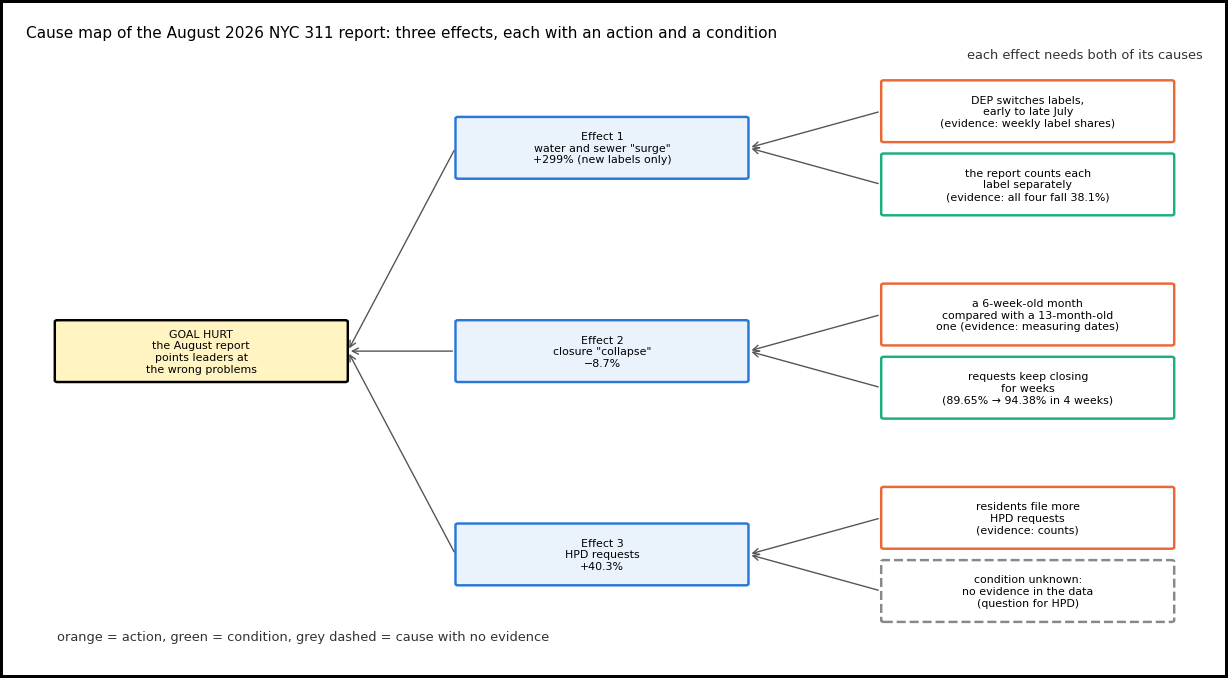

In [7]:
from matplotlib.patches import FancyBboxPatch

def box(ax, x, y, text, kind):
    style = {"effect": ("#eaf2fc", BLUE, "-"), "action": ("white", ORANGE, "-"), "condition": ("white", AQUA, "-"),
             "missing": ("white", GREY, "--"), "goal": ("#fff4c2", "black", "-")}[kind]
    ax.add_patch(FancyBboxPatch((x - 1.15, y - 0.36), 2.3, 0.72, boxstyle="round,pad=0.02", fc=style[0], ec=style[1], lw=1.6, ls=style[2]))
    ax.text(x, y, text, ha="center", va="center", fontsize=7.2)

def link(ax, x1, y1, x2, y2):
    ax.annotate("", xy=(x1 + 1.17, y1), xytext=(x2 - 1.17, y2), arrowprops=dict(arrowstyle="->", color="#555555", lw=0.9))

fig, ax = plt.subplots(figsize=(11, 6))
box(ax, 0, 0, "GOAL HURT\nthe August report\npoints leaders at\nthe wrong problems", "goal")
effects = [(2.5, "Effect 1\nwater and sewer \"surge\"\n+299% (new labels only)", [
               ("action", "DEP switches labels,\nearly to late July\n(evidence: weekly label shares)"),
               ("condition", "the report counts each\nlabel separately\n(evidence: all four fall 38.1%)")]),
           (0, "Effect 2\nclosure \"collapse\"\n−8.7%", [
               ("action", "a 6-week-old month\ncompared with a 13-month-old\none (evidence: measuring dates)"),
               ("condition", "requests keep closing\nfor weeks\n(89.65% → 94.38% in 4 weeks)")]),
           (-2.5, "Effect 3\nHPD requests\n+40.3%", [
               ("action", "residents file more\nHPD requests\n(evidence: counts)"),
               ("missing", "condition unknown:\nno evidence in the data\n(question for HPD)")])]
for y, label, causes in effects:
    box(ax, 3.2, y, label, "effect"); link(ax, 0, 0, 3.2, y)
    for k, (kind, text) in enumerate(causes):
        cy = y + (0.45 if k == 0 else -0.45)
        box(ax, 6.6, cy, text, kind); link(ax, 3.2, y, 6.6, cy)
ax.text(-1.15, -3.55, "orange = action, green = condition, grey dashed = cause with no evidence", fontsize=8.5, color="#333333")
ax.text(8.0, 3.6, "each effect needs both of its causes", ha="right", fontsize=8.5, color="#333333")
ax.set_xlim(-1.4, 8.0); ax.set_ylim(-3.7, 3.75); ax.axis("off")
ax.set_title("Cause map of the August 2026 NYC 311 report: three effects, each with an action and a condition", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

**Observation:** each headline has its own pair of causes, and none of the three pairs shares a cause with another. One report hid three separate problems: two in how the report measures, one in the city itself.

**Conclusion:** two of the three alarming headlines are produced by how the report measures, not by worse service. The third (HPD) is a rise in filed requests whose condition is still unknown.

### Where to put the fix

A fix can go at any cause. The useful question per effect: which of its two causes is easier to remove?

| effect | cause | can it be removed? | the fix |
|---|---|---|---|
| 1. water and sewer "surge" | action: DEP relabels | no: the relabel was DEP's own decision | — |
| | condition: labels counted separately | **yes** | add a table that maps old labels to new ones, and count them together |
| 2. closure "collapse" | action: unequal ages compared | **yes** | always compare months at the same age (e.g. 6 weeks each) |
| | condition: requests keep closing for weeks | no: it is how the work happens | — |
| 3. HPD requests | action: more requests filed | not by the report: the requests were really filed | — |
| | condition: unknown | first find it | take the question to HPD before choosing a fix |

**Conclusion:** for effect 1 the fix is at the condition. For effect 2 it is at the action. That is the point of mapping both causes: the cheapest place to break a chain is not always the "deepest" cause (the one furthest back in the chain, which the 5 Whys digs for).

## Exercise — A manager's claim

A manager reads the closure figures and says: *"Our agencies got slower this year. That's why only 89.65% of August's requests are closed, against 98.19% last year."*

1. Where does this claim sit on the cause map, and how many of the 8.54 points can it explain at most?
2. Before accepting even that part, check the other cause from the Effect 2 Hypothesis: did the mix of requests change? Use HPD, which grew the most.

In [8]:
hpd25, hpd26 = d["hpd_august_types"].groupby("month")["n"].sum()[["2025-08", "2026-08"]]
print("1. Most the claim can explain = the gap left at equal age (6 weeks each):")
print(f"   {s[2]:.2%} − {s[1]:.2%} = {(s[2] - s[1]) * 100:.2f} points of {(s[0] - s[1]) * 100:.2f}")
print()
print("2. HPD's share of all August requests:")
print(f"   August 2025 = {hpd25:,} of {r25:,} = {hpd25 / r25:.1%}")
print(f"   August 2026 = {hpd26:,} of {r26:,} = {hpd26 / r26:.1%}")

1. Most the claim can explain = the gap left at equal age (6 weeks each):
   92.01% − 89.65% = 2.36 points of 8.54

2. HPD's share of all August requests:
   August 2025 = 40,078 of 304,039 = 13.2%
   August 2026 = 56,216 of 328,914 = 17.1%


**Answer:**
1. The claim is a new cause under effect 2, on its own branch next to the pair already on the map. At most it explains 2.36 of the 8.54 points: the rest (6.18) comes from the unequal ages.
2. HPD went from 13.2% to 17.1% of all August requests. If HPD closes requests more slowly than the average agency, this shift alone lowers the overall share closed, with no agency getting slower.

**Hypothesis:** the 2.36 points are part slowdown, part request mix. On the map, the manager's claim stays a cause with missing evidence until closure is compared agency by agency, at equal age.

## Key takeaways

- **Every effect has at least two causes: an action and a condition.** The water-and-sewer "surge" needed both the relabel and a report that counts labels separately.
- **A cause map branches from one goal.** One report hid three separate effects, each with its own pair of causes.
- **Every cause carries evidence, or is marked as missing it.** HPD requests rose 40.3%, but the condition behind it is unknown: the map shows the gap instead of guessing.
- **The fix can go at either cause.** For the "surge" the fix is at the condition (count old and new labels together). For the closure "collapse" it is at the action (compare months at equal age).
- **Most of the closure "collapse" was the comparison.** 6.18 of the 8.54 points came from unequal ages. At equal age the gap is 2.36 points, and part of that may be request mix.
- **In DMAIC, this is Analyze, and it prepares Improve:** the map shows where each fix can go.